# Problem 1.2: learning cellular automaton updates

In [289]:
import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt
from itertools import product
import itertools

# Used to improve the display of numpy arrays in the notebook
# Places where rounding applies have been marked in the output
# np.set_printoptions(suppress=True, precision=4)

## Task 1.2.1

In [290]:
def ruleToBinary(rule):
    # turn rule decimal into binary representation
    return [int(b) for b in format(rule, '08b')] # ensure it's 8 bits long

def calculateState(left, current, right, ruleBits):
    # turn the three states into a binary number
    index = 4*left + 2*current + right
    return ruleBits[7-index]  # 7-index because the rule is defined in reverse order

def runCellularAutomaton(rule, base, numGens = 64):
    numColumns = len(base)
    ruleBinary = ruleToBinary(rule) # Convert rule to binary representation

    result = np.zeros((numGens, numColumns), dtype=int)
    result[0] = base  # Set the initial state
    
    for i in range(numGens - 1):                     
        for j in range(numColumns):
            left    = result[i, j-1]
            current = result[i, j]
            right   = result[i, (j+1) % numColumns]

            newState = calculateState(left, current, right, ruleBinary)
            result[i+1, j] = newState

    return result

def plotCellularAutomaton(rule, base):
    array = runCellularAutomaton(rule, base)
    plt.figure(figsize=(8, 4))
    plt.imshow(array, cmap='gray_r', interpolation='nearest')  # 0 = white, 1 = black
    plt.title(f'rule {rule}')
    plt.axis('off')
    plt.show()

In [291]:
ruleA = 60
ruleB = 102
base = np.random.randint(0,2,127)

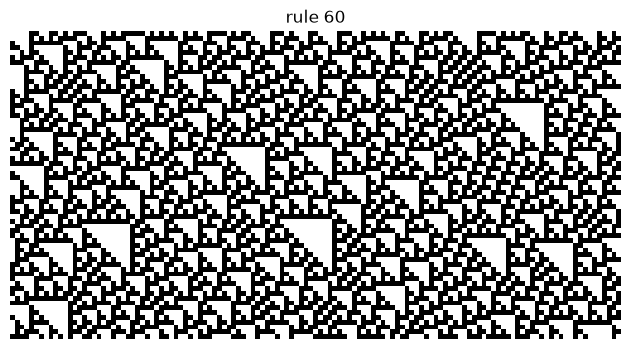

In [292]:
plotCellularAutomaton(ruleA, base)

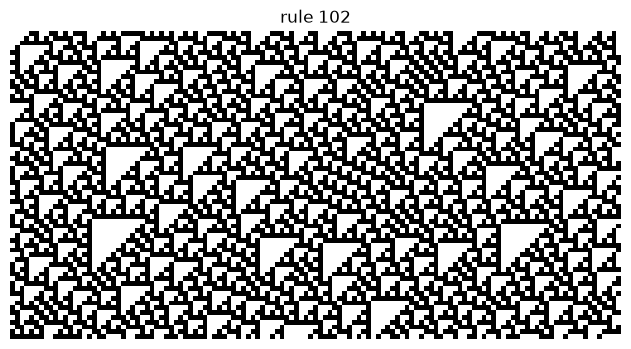

In [293]:
plotCellularAutomaton(ruleB, base)

## Task 1.2.2

In [294]:
ruleC = 110
ruleD = 126

# Create the matrix of all possible 3-bit combinations
matXT = np.array(list(product([0,1], repeat=3)))

# Convert rules to binary and reverse them for proper indexing
ruleC_bits = np.array(ruleToBinary(ruleC))[::-1]
ruleD_bits = np.array(ruleToBinary(ruleD))[::-1]

# Convert to bipolar representation
matXT_bipolar = (-1) ** matXT
ruleC_bipolar = (-1) ** ruleC_bits
ruleD_bipolar = (-1) ** ruleD_bits

# Solve for the weight vectors using least squares
vecW_starC = la.lstsq(matXT_bipolar, ruleC_bipolar, rcond=None)[0]
vecW_starD = la.lstsq(matXT_bipolar, ruleD_bipolar, rcond=None)[0]

# Compute the outputs for both rules using the weight vectors
vecYroofA = matXT_bipolar @ vecW_starC
vecYroofB = matXT_bipolar @ vecW_starD

In [295]:
print('matXT: \n' , matXT)

print('')

print('vecY_C: (Rule 110)', ruleC_bipolar)
print('vecY_D: (Rule 126)', ruleD_bipolar)

print('')

print('vecW*C: (Rule 110)', vecW_starC)
print('vecW*D: (Rule 126)', vecW_starD)

print('')

print('vecY^C: (Rule 110)')
print(vecYroofA)
print('vecY^D: (Rule 126)')
print(vecYroofB)

# print('')
# print("The values in 'vecY_D' and 'vecY^D' are calculated as small numbers due to floating-point rounding. " ,
#      "They have been rounded to zeros for readability.")

matXT: 
 [[0 0 0]
 [0 0 1]
 [0 1 0]
 [0 1 1]
 [1 0 0]
 [1 0 1]
 [1 1 0]
 [1 1 1]]

vecY_C: (Rule 110) [ 1 -1 -1 -1  1 -1 -1  1]
vecY_D: (Rule 126) [ 1 -1 -1 -1 -1 -1 -1  1]

vecW*C: (Rule 110) [-0.25  0.25  0.25]
vecW*D: (Rule 126) [0. 0. 0.]

vecY^C: (Rule 110)
[ 0.25 -0.25 -0.25 -0.75  0.75  0.25  0.25 -0.25]
vecY^D: (Rule 126)
[ 0. -0.  0. -0.  0. -0.  0. -0.]


## Task 1.2.3

In [296]:
def phi(x):
    x = np.asarray(x)
    n = len(x)
    result = []

    for k in range(0, n+1):
        # Generate all combinations of indices of length k
        for S in itertools.combinations(range(n), k):
            # Multiply the elements of x at the indices in S
            product = np.prod(x[list(S)])
            result.append(product)
    
    return np.array(result)

In [297]:
vecA = np.array([1,2,3])
phiA = phi(vecA)

print('vecA:', vecA)
print('phi(A):', phiA)

vecA: [1 2 3]
phi(A): [1 1 2 3 2 3 6 6]


## Task 1.2.4

In [298]:
matPhi = np.array([phi(x) for x in matXT_bipolar])

vecW_starC_new = la.lstsq(matPhi, ruleC_bipolar, rcond=None)[0]
vecW_starD_new = la.lstsq(matPhi, ruleD_bipolar, rcond=None)[0]

vecYroofA_new = matPhi @ vecW_starC_new
vecYroofB_new = matPhi @ vecW_starD_new

In [299]:
print ('matPhi: \n', matPhi)

print('')

print('vecW*C_new: (Rule 110)', vecW_starC_new)
print('vecW*D_new: (Rule 126)', vecW_starD_new)

print('')
print('vecY^C_new: (Rule 110)')
print(vecYroofA_new)

print('vecY^D_new: (Rule 126)')
print(vecYroofB_new)

# print('')
# print('The values in 'vecW*D_new' and 'vecY^D_new' have been rounded.')

matPhi: 
 [[ 1  1  1  1  1  1  1  1]
 [ 1  1  1 -1  1 -1 -1 -1]
 [ 1  1 -1  1 -1  1 -1 -1]
 [ 1  1 -1 -1 -1 -1  1  1]
 [ 1 -1  1  1 -1 -1  1 -1]
 [ 1 -1  1 -1 -1  1 -1  1]
 [ 1 -1 -1  1  1 -1 -1  1]
 [ 1 -1 -1 -1  1  1  1 -1]]

vecW*C_new: (Rule 110) [-0.25 -0.25  0.25  0.25  0.25  0.25  0.75 -0.25]
vecW*D_new: (Rule 126) [-0.5 -0.   0.   0.   0.5  0.5  0.5  0. ]

vecY^C_new: (Rule 110)
[ 1. -1. -1. -1.  1. -1. -1.  1.]
vecY^D_new: (Rule 126)
[ 1. -1. -1. -1. -1. -1. -1.  1.]


Comparison to previous results:
- Instead of a zeroes vector for Rule 126 (D), we get a more reasonable result.
- Previous zero vector basically meant, that no feature is used.

Trade-off:
- Higher feature dimension (exponential growth) 
- less interpretable features (domain specific meaning is lost)
